# Entrenamiento final, evaluación en test y serialización
Entrada: `datos/model/*` + `modelo/mejores_parametros.json` (del cuadernillo 03).
Salida: `modelo/modelo_final.joblib` + `modelo/modelo_final_metadatos.json`.

Es la **única** vez que se usa el conjunto de test.

In [ ]:
# === Solo Google Colab (en Jupyter local esta celda no hace nada) ===
import os, sys, subprocess
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    # Ajusta esta ruta si subiste la carpeta a otro lugar de tu Drive
    RUTA_PROYECTO = "/content/drive/MyDrive/proyecto-clasificacion-musical"
    os.chdir(RUTA_PROYECTO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # os.environ["MODO_RAPIDO"] = "1"   # descomenta para una corrida rápida (~10 min en vez de ~85)

In [1]:
# === Configuración común ===
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "funciones.py").exists())
sys.path.insert(0, str(RAIZ / "src"))
import funciones as F

warnings.filterwarnings("ignore", message=".*Early stopping criterion not reached.*")  # IterativeImputer
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
rutas = F.obtener_rutas(RAIZ)
# MODO_RAPIDO=1 (variable de entorno) reduce muestras y presupuestos para iterar rápido.
MODO_RAPIDO = os.environ.get("MODO_RAPIDO", "0") == "1"
print("Raíz:", rutas.raiz, "| modo rápido:", MODO_RAPIDO)

Raíz: <raíz> | modo rápido: False


In [2]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier

X_train, X_test, y_train_txt, y_test_txt = F.cargar_conjuntos(rutas)
le, (y_train, y_test) = F.codificar_objetivo(y_train_txt, y_test_txt)
CLASES = le.classes_.tolist()
config = F.cargar_json(rutas.modelo / "mejores_parametros.json")
params = config["parametros"]
print(config["estrategia"], "| F1-macro CV:", round(config["f1_macro_cv"], 4), "| calibrar:", config["calibrar_isotonica"])
F.tabla_significado(params)

Optuna (TPE) | F1-macro CV: 0.8194 | calibrar: False


,valor,significado
hiperparámetro,,
n_estimators,295.0000,Nº de árboles M en F_M(x)=Σ η·f_m(x). Más árbo...
learning_rate,0.0173,Shrinkage η: cada árbol corrige solo una fracc...
num_leaves,54.0000,Hojas por árbol = nº de regiones en que cada á...
max_depth,6.0000,Profundidad máxima: orden máximo de interacció...
min_child_samples,105.0000,Mínimo de filas por hoja: regulariza fronteras...
subsample,0.5788,Fracción de filas por árbol (boosting estocást...
colsample_bytree,0.8576,Fracción de columnas por árbol: obliga a usar ...
reg_lambda,0.6754,Penalización L2 sobre los pesos de las hojas: ...


## 1. Entrenamiento con todo train
Se ajustan tres versiones: el piso (Dummy), el LightGBM optimizado y el LightGBM con calibración isotónica (5-fold interno: cada calibrador se ajusta con datos que su modelo no vio).

In [3]:
base = F.construir_pipeline(LGBMClassifier(subsample_freq=1, random_state=F.SEMILLA, verbose=-1, n_jobs=-1)
                            ).set_params(**params)
modelos = {
    "Dummy (prior)": F.construir_pipeline(DummyClassifier(strategy="prior")).fit(X_train, y_train),
    "LightGBM": base.fit(X_train, y_train),
    "LightGBM calibrado": CalibratedClassifierCV(F.construir_pipeline(
        LGBMClassifier(subsample_freq=1, random_state=F.SEMILLA, verbose=-1, n_jobs=-1)).set_params(**params),
        method="isotonic", cv=3 if MODO_RAPIDO else 5).fit(X_train, y_train),
}
metricas, probas = F.evaluar_en_test(modelos, X_train, y_train, X_test, y_test)
metricas

f1_macro  accuracy  roc_auc_ovr  log_loss  brier  \
modelo             conjunto                                                     
Dummy (prior)      train       0.0195    0.1079       0.5000    2.2999 0.8995   
                   test        0.0195    0.1078       0.5000    2.2999 0.8995   
LightGBM           train       0.9109    0.9169       0.9963    0.2094 0.1194   
                   test        0.8304    0.8406       0.9883    0.3556 0.1978   
LightGBM calibrado train       0.9008    0.9092       0.9959    0.2339 0.1339   
                   test        0.8276    0.8411       0.9886    0.3563 0.1987   

                               ece  
modelo             conjunto         
Dummy (prior)      train    0.0000  
                   test     0.0001  
LightGBM           train    0.0452  
                   test     0.0170  
LightGBM calibrado train    0.0629  
                   test     0.0243

**Control final de sobreajuste:** la brecha train–test del LightGBM debe ser similar a la brecha train–validación del cuadernillo 03.

**Elección sin mirar el test:** la versión que se serializa (calibrada o no) la decidió el cuadernillo 03 con log-loss *out-of-fold*. Elegirla ahora por su métrica de test convertiría al test en un conjunto de validación y su cifra dejaría de ser una estimación honesta. Las dos se muestran solo por transparencia.

In [4]:
m = metricas.xs("test", level="conjunto")
ganador = "LightGBM calibrado" if config["calibrar_isotonica"] else "LightGBM"
modelo_final, p_test = modelos[ganador], probas[ganador]
print("Modelo final:", ganador, "| F1 CV:", round(config["f1_macro_cv"], 4), "| F1 test:", round(m.loc[ganador, "f1_macro"], 4))

Modelo final: LightGBM | F1 CV: 0.8194 | F1 test: 0.8304


## 2. Diagnóstico en test

In [5]:
pred = p_test.argmax(1)
F.reporte_clasificacion(y_test, pred, CLASES)

,precision,recall,f1-score,support
Alternative,0.7653,0.7350,0.7499,883.0000
Anime,0.9899,0.9799,0.9849,996.0000
Blues,0.8979,0.9099,0.9039,966.0000
Classical,0.9785,0.9627,0.9706,993.0000
Country,0.8768,0.9035,0.8899,953.0000
Electronic,0.9228,0.9388,0.9308,981.0000
Hip-Hop,0.6061,0.7011,0.6501,823.0000
Jazz,0.8909,0.8715,0.8811,965.0000
Rap,0.6424,0.5254,0.5781,807.0000
Rock,0.7473,0.7824,0.7644,873.0000


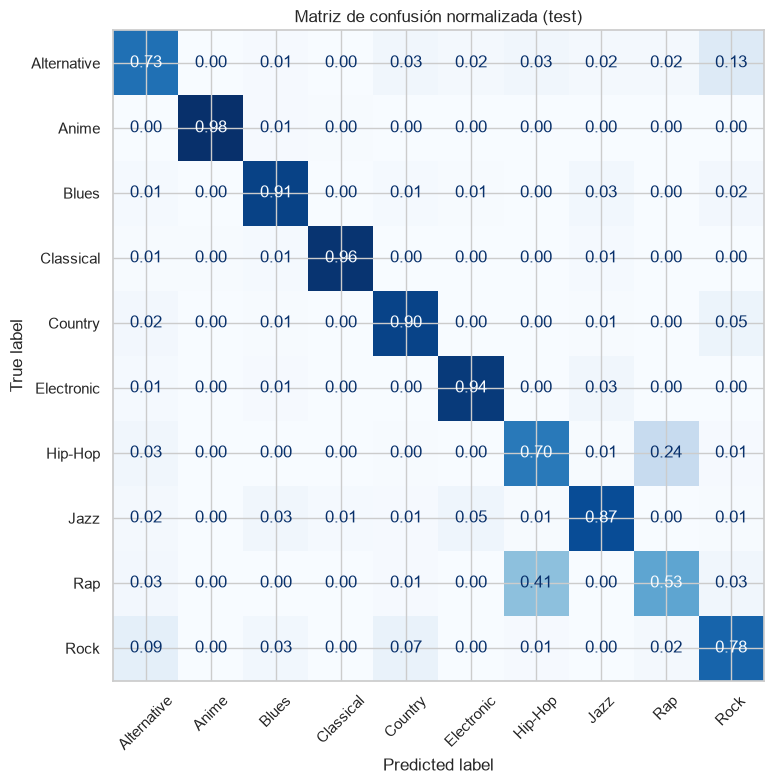

In [6]:
fig = F.grafico_matriz_confusion(y_test, pred, CLASES)

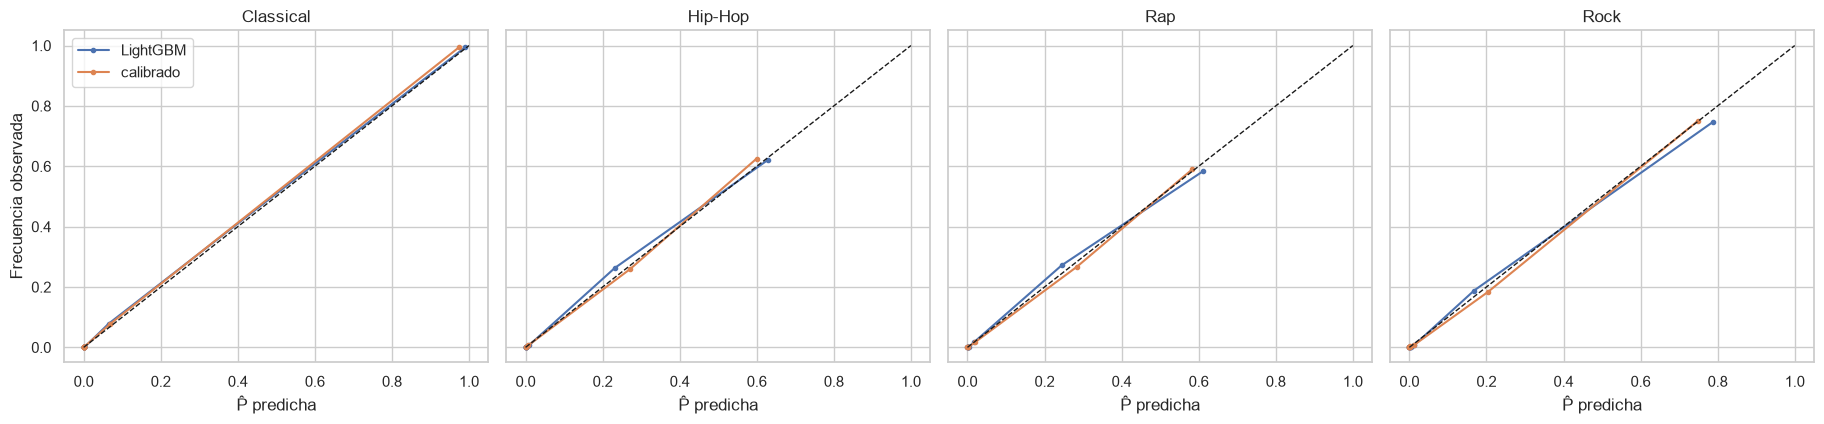

In [7]:
fig = F.grafico_confiabilidad(y_test, {"LightGBM": probas["LightGBM"], "calibrado": probas["LightGBM calibrado"]},
                               CLASES, ["Classical", "Hip-Hop", "Rap", "Rock"])

**Lectura:** con el presupuesto completo, el F1-macro de test (0.830) queda cerca del de CV (0.819). Que el test sea algo mayor es esperable: el modelo final se entrena con todo train (25 % más filas que cada fold), y el Target Encoding del artista mejora con más canciones por artista. Si el cuadernillo 03 corrió en modo rápido (CV sobre 6 000 filas), la distancia es mayor por ese mismo motivo.

Los errores se concentran en dos pares que el EDA ya anticipaba: **Rap↔Hip-Hop** y **Rock↔Alternative** (y en parte Country). Comparten canciones en el dataset original, así que es un límite de las etiquetas, no del modelo. Classical, Anime y Electronic se separan casi por completo.

## 3. Importancia por permutación (en test, sobre columnas originales)

,importancia_media,std
artist_name,0.6548,0.0027
popularity,0.0841,0.0048
instrumentalness,0.0105,0.0012
danceability,0.0094,0.0023
acousticness,0.0052,0.0023
speechiness,0.0047,0.0023
loudness,0.0023,0.0030
valence,0.0021,0.0010
liveness,0.0013,0.0006
key,0.0013,0.0006


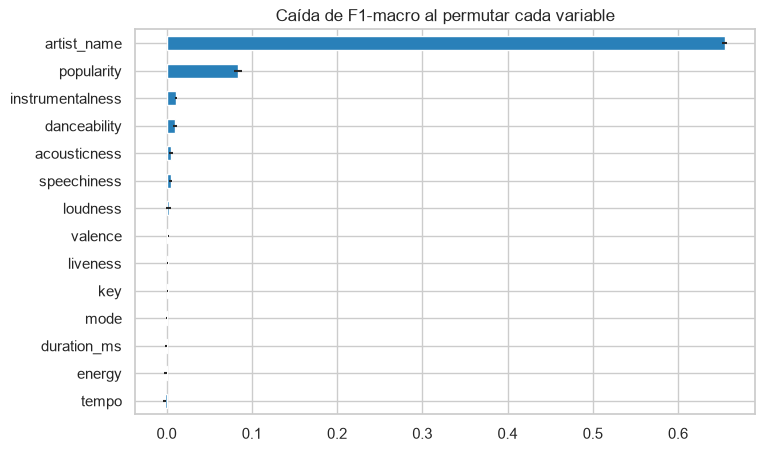

In [8]:
imp = F.importancia_permutacion(modelo_final, X_test, y_test, n_repeticiones=3 if MODO_RAPIDO else 5,
                                muestra=2000 if MODO_RAPIDO else 4000)
ax = imp["importancia_media"].sort_values().plot.barh(xerr=imp["std"], figsize=(8, 5), color="#2980b9",
                                                       title="Caída de F1-macro al permutar cada variable")
imp

**Lectura:** `artist_name` domina (permutarlo hace caer el F1-macro unos 60 puntos), seguido de `popularity`. Las variables acústicas aparecen con importancia cercana a cero, pero **no porque sean inútiles**: son redundantes con el artista y, al permutar una sola, el modelo la sustituye con las demás. El modelo sin artista de la sección siguiente es quien muestra cuánto valen por sí solas.

## 3b. Modelo para artistas nuevos (sin `artist_name`)
Mismos hiperparámetros, sin la rama de artista. Es la cifra que corresponde a un lanzamiento de un artista que no está en el catálogo.

In [9]:
modelo_nuevos = F.construir_pipeline(LGBMClassifier(subsample_freq=1, random_state=F.SEMILLA, verbose=-1, n_jobs=-1),
                                     codificacion_artista="ninguna").set_params(**params).fit(X_train, y_train)
met_nuevos, _ = F.evaluar_en_test({"LightGBM sin artista": modelo_nuevos}, X_train, y_train, X_test, y_test)
met_nuevos

f1_macro  accuracy  roc_auc_ovr  log_loss  \
modelo               conjunto                                              
LightGBM sin artista train       0.6849    0.6904       0.9593    0.8505   
                     test        0.6068    0.6146       0.9390    1.0003   

                               brier    ece  
modelo               conjunto                
LightGBM sin artista train    0.4291 0.0823  
                     test     0.4960 0.0219

**Ojo con esta cifra:** el test es un split estratificado por género, **no por artista**. Muchos artistas del test tienen otras canciones en train, y el modelo los reconoce indirectamente por su `popularity` y su firma acústica. Por eso el F1 de test sin artista (~0.61) es algo optimista. La cifra honesta para artistas realmente nuevos es la de `StratifiedGroupKFold` del cuadernillo 03 (~0.595).

## 4. Serialización y prueba de inferencia
Se guarda el **pipeline completo** (imputación + ingeniería + codificación + escalado + modelo + calibración) junto con el LabelEncoder. Así, en producción solo hay que aplicar las reglas sin estado (centinelas → NaN) que hace `F.predecir_genero`.

In [10]:
rutas_guardadas = F.serializar_modelo(modelo_final, le, m.loc[ganador].to_dict(),
                                      {"modelo": ganador, **params}, rutas)
F.serializar_modelo(modelo_nuevos, le, met_nuevos.xs("test", level="conjunto").iloc[0].to_dict(),
                    {"modelo": "LightGBM sin artista", **params}, rutas, nombre="modelo_artistas_nuevos")
rutas_guardadas

{'modelo': WindowsPath('<raíz>/modelo/modelo_final.joblib'),
 'metadatos': WindowsPath('<raíz>/modelo/modelo_final_metadatos.json')}

In [11]:
# Prueba de humo: registros crudos del CSV original (incluye centinelas -1 / '?' / 'empty_field')
modelo_cargado, le_cargado = F.cargar_modelo(rutas_guardadas["modelo"])
raw = F.cargar_raw(rutas.raw / "music_genre.csv").dropna(how="all")
muestra = pd.concat([raw[raw.tempo == "?"].head(3), raw[raw.duration_ms == -1].head(3),
                     raw[raw.artist_name == "empty_field"].head(2)])
F.predecir_genero(modelo_cargado, le_cargado, muestra.drop(columns=[F.OBJETIVO])).assign(real=muestra[F.OBJETIVO].values)

,top1,p1,top2,p2,top3,p3,real
5,Electronic,0.9889,Jazz,0.0046,Alternative,0.0035,Electronic
32,Electronic,0.9941,Alternative,0.0038,Jazz,0.0009,Electronic
35,Electronic,0.9980,Alternative,0.0003,Jazz,0.0003,Electronic
0,Electronic,0.9938,Alternative,0.0025,Jazz,0.0013,Electronic
13,Electronic,0.9897,Jazz,0.0058,Alternative,0.0009,Electronic
16,Electronic,0.9593,Rock,0.0156,Rap,0.0084,Electronic
19,Electronic,0.6895,Jazz,0.1524,Rock,0.0688,Electronic
25,Electronic,0.8997,Anime,0.0460,Blues,0.0258,Electronic


**Nota:** esas filas del CSV pueden pertenecer al train, así que la prueba de humo verifica que el pipeline funcione de punta a punta con datos crudos y centinelas, no el rendimiento del modelo. El rendimiento es el del bloque de test anterior.